# Plot KAM vs distance to GB

In [11]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import distance_transform_edt, binary_dilation
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

### Import files

In [12]:
small_microstructure = False
larger_microstructure = False
section = True
slice_24 = False
slice_50 = False

file_path = 'E:/Users/lagon/OneDrive - The University of Manchester/Laura Chat/Simulations/KAM_distance_hydride_GB'

if small_microstructure:
    #file_path = 'E:/Users/lagon/The University of Manchester Dropbox/Laura Gonzalez/Zr-hydrides/Lunty polish/Lunty avec tickle/Laura analysis Part 1/3D microstructure analysis'
    file_name = file_path + "/4.5-Recrystallised_rotated_aligned_cleaned_KAM_boundarycells.dream3d"
    KAM_path = "/DataContainers/ImageDataContainer/CellData/KAM"
    boundary_cells = "/DataContainers/ImageDataContainer/CellData/BoundaryCells"
    hydphase, Zrphase = 1, 2
    z = 850  # pick a slice that contains hydrides + GBs to visualise the threshold used for GBs flagged as far from hydrides


if larger_microstructure:
    #file_path = 'E:/Users/lagon/The University of Manchester Dropbox/Laura Gonzalez/Zr-hydrides/Larger_alloy4_processing/'
    file_name = file_path + "/4-LargeRecrystallised_rotated_aligned_cleaned_KAM_boundarycells.dream3d"
    KAM_path = "/DataContainers/ImageDataContainer/CellData/KAM"
    boundary_cells = "/DataContainers/ImageDataContainer/CellData/BoundaryCells"
    hydphase, Zrphase = 2, 1
    z = 850  # pick a slice that contains hydrides + GBs to visualise the threshold used for GBs flagged as far from hydrides


if section:
    #file_path = 'E:/Users/lagon/The University of Manchester Dropbox/Laura Gonzalez/Zr-hydrides/Lunty polish/Lunty avec tickle/Laura analysis Part 1/3D microstructure analysis'
    #file_name = file_path + "/4.5-Recrystallised_rotated_aligned_cleaned_KAM_boundarycells_block.dream3d"
    file_name = file_path + "/4.5-Recrystallised_rotated_aligned_cleaned_KAM_boundarycells_block.dream3d"
    KAM_path = "/DataContainers/ImageDataContainer/CellData/KAM"
    boundary_cells = "/DataContainers/ImageDataContainer/CellData/BoundaryCells"
    hydphase, Zrphase = 1, 2

if slice_24:
    #file_path = 'E:/Users/lagon/The University of Manchester Dropbox/Laura Gonzalez/Zr-hydrides/Lunty polish/Lunty avec tickle/Laura analysis Part 1/3D microstructure analysis'
    file_name = file_path + "/4.5-Recrystallised_rotated_aligned_cleaned_KAM_boundarycells_block_slice24.dream3d"
    KAM_path = "/DataContainers/ImageDataContainer/CellData/KAM"
    boundary_cells = "/DataContainers/ImageDataContainer/CellData/BoundaryCells"
    hydphase, Zrphase = 1, 2

if slice_50:
    #file_path = 'E:/Users/lagon/The University of Manchester Dropbox/Laura Gonzalez/Zr-hydrides/Lunty polish/Lunty avec tickle/Laura analysis Part 1/3D microstructure analysis'
    file_name = file_path + "/4.5-Recrystallised_rotated_aligned_cleaned_KAM_boundarycells_block_slice50.dream3d"
    KAM_path = "/DataContainers/ImageDataContainer/CellData/KAM"
    boundary_cells = "/DataContainers/ImageDataContainer/CellData/BoundaryCells"
    hydphase, Zrphase = 1, 2


with h5py.File(file_name, "r") as f:
    kam_values = f[KAM_path][()]
    phases_values = f["/DataContainers/ImageDataContainer/CellData/Phases"][()]
    voxel_size = f["/DataContainers/ImageDataContainer/_SIMPL_GEOMETRY/SPACING"][()]
    phases_names = f["/DataContainers/ImageDataContainer/CellEnsembleData/MaterialName"][()]
    boundary_cells = f[boundary_cells][()]
    grainID = f["/DataContainers/ImageDataContainer/CellData/FeatureIds"][()]

kam_values = np.asarray(kam_values, dtype=float)
phases_values = np.asarray(phases_values)
voxel_size = np.asarray(voxel_size, dtype=float)
boundary_cells = np.array(boundary_cells)    
grainIDs = np.array(grainID)

# Check that phase number corresponds to the correct label
print(phases_names)
print(hydphase, Zrphase)

[b'Invalid Phase' b'ZircHydride' b'Zirc-alloy4']
1 2


### Tidy up data

In [13]:
def binned_mean(x, y, bins):
    idx = np.digitize(x, bins)
    means = np.full(len(bins) - 1, np.nan, dtype=float)
    for i in range(1, len(bins)):
        m = (idx == i)
        if np.any(m):
            means[i - 1] = np.mean(y[m])
    centers = (bins[:-1] + bins[1:]) / 2
    return centers, means

def to_3d_scalar(a):
    a = np.asarray(a)
    if a.ndim == 4:
        return a[..., 0]
    return a

ph  = to_3d_scalar(phases_values)
kam = to_3d_scalar(kam_values)
bc  = to_3d_scalar(boundary_cells)

zr_mask  = (ph == Zrphase)          
hyd_mask = (ph == hydphase)   
gb_all   = (bc >= 1)      

voxel_spacing = tuple(np.asarray(voxel_size, dtype=float))


## Plot KAM vs distance to hyd-Zr GB and vs distance to Zr-Zr GB

<>:92: SyntaxWarning: invalid escape sequence '\d'
<>:92: SyntaxWarning: invalid escape sequence '\d'
C:\Users\lagon\AppData\Local\Temp\ipykernel_17864\3397678749.py:92: SyntaxWarning: invalid escape sequence '\d'
  plt.ylabel("Average Zr KAM ($\degree$)", fontsize=24, fontweight='bold')
C:\Users\lagon\AppData\Local\Temp\ipykernel_17864\3397678749.py:90: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=24)


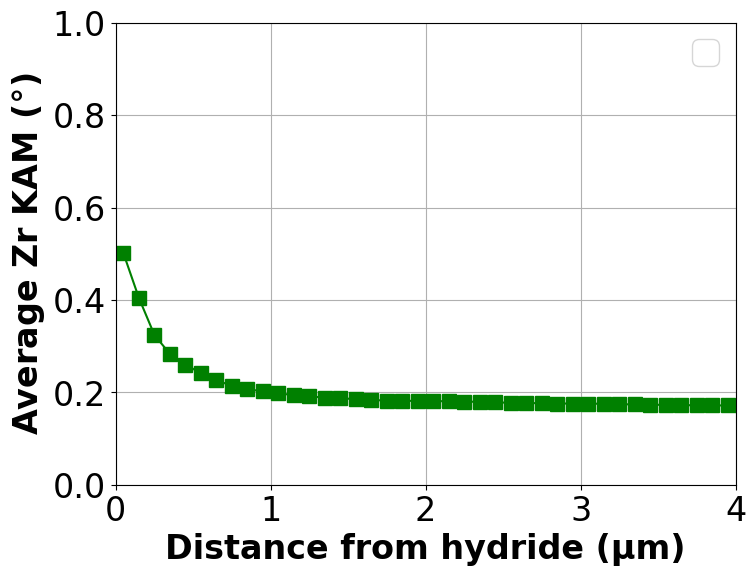

In [14]:
##  ZR–HYD GB DISTANCES 

# GB voxels of the Zr phase (includes Zr-Zr and Zr-hyd GB)
gb_in_zr = gb_all & zr_mask

# Define "touching hydride" using a 3x3x3 neighborhood (includes diagonals)
hyd_touch = binary_dilation(hyd_mask, structure=np.ones((3, 3, 3), dtype=bool))

# GB voxels in Zr that touch hydride
gb_zr_hyd = gb_in_zr & hyd_touch

# Distance from each Zr voxel to nearest Zr-hyd GB voxel
dist_gb_hyd_vol = distance_transform_edt(~gb_zr_hyd, sampling=voxel_spacing)
dist_gb_hyd = dist_gb_hyd_vol[zr_mask]



## ZR–ZR GB DISTANCES, only those >= 2.4 µm from hydrides

# KAM values of Zr phase
kam_zr = kam[zr_mask]
kam_zr = kam[zr_mask] # KAM for Zr voxels 
gb_in_zr = gb_all & zr_mask # Zr–Zr GB voxels 

# "Touches hydride" in a 3x3x3 neighborhood (includes diagonals)
hyd_touch = binary_dilation(hyd_mask, structure=np.ones((3,3,3), dtype=bool))

# Zr–Zr GB = GB voxels in Zr that do NOT touch hydride
gb_zr_zr = gb_in_zr & (~hyd_touch)

# Distance-to-hydride
dist_to_hyd_um_vol = distance_transform_edt(~hyd_mask, sampling=voxel_spacing)

# Threshold: plot only Zr–Zr GB voxels >= 2.4 microns from hydrides
R_um = 2.4

# distance to hydride everywhere 
dist_to_hyd_um_vol = distance_transform_edt(~hyd_mask, sampling=voxel_spacing)

# clean GB voxels
gb_zr_zr_far = gb_zr_zr & (dist_to_hyd_um_vol >= R_um)

# recompute distance to clean GB
dist_to_gb_far_vol = distance_transform_edt(~gb_zr_zr_far, sampling=voxel_spacing)

# important! only consider Zr voxels that are also far from hydrides
zr_far_mask = zr_mask & (dist_to_hyd_um_vol >= R_um)
kam_zr_far = kam[zr_far_mask]
dist_to_gb_far = dist_to_gb_far_vol[zr_far_mask]



## Set bins for plotting

bin_width = 0.1
max_dist = 30.0
bins = np.arange(0.0, max_dist + bin_width, bin_width)
bin_centers_hydgb, bin_means_hydgb = binned_mean(dist_gb_hyd, kam_zr, bins)
bin_centers, bin_means = binned_mean(dist_to_gb_far, kam_zr_far, bins)



## Plot the graphs

plt.figure(figsize=(8, 6))


if small_microstructure or larger_microstructure:
    plt.figure(figsize=(8,6))
    plt.xlabel("Distance from grain boundary (µm)", fontsize=24, fontweight='bold')
    valid = ~np.isnan(bin_means)
    valid_h = ~np.isnan(bin_means_hydgb)

    plt.plot(bin_centers_hydgb[valid_h], bin_means_hydgb[valid_h],
            marker='s', color='green', markersize=10, label='GBs with hydride')

    plt.plot(bin_centers[valid], bin_means[valid],
            marker='o', color='black', markersize=10, label='GBs without hydride')

    #plt.plot(bin_centers, bin_means, marker='o', color='black', markersize=10, label=f'distance from GB')
    #plt.plot(bin_centers_hydgb, bin_means_hydgb, marker='s', color='green', markersize=10, label='distance from hydride')
    plt.legend(fontsize=18)


if section or slice_24 or slice_50:
    plt.xlabel("Distance from hydride (µm)", fontsize=24, fontweight='bold')
    plt.plot(bin_centers_hydgb, bin_means_hydgb, marker='s', color='green', markersize=10)


plt.legend(fontsize=24)

plt.ylabel("Average Zr KAM ($\degree$)", fontsize=24, fontweight='bold')
plt.tick_params(axis='both', which='major', labelsize=24)

plt.xlim([0, 4])
plt.ylim([0, 1])
plt.grid(True)

plt.show()
plt.show()


## KAM OR vs No OR

<>:48: SyntaxWarning: invalid escape sequence '\d'
<>:48: SyntaxWarning: invalid escape sequence '\d'
C:\Users\lagon\AppData\Local\Temp\ipykernel_17864\1021989810.py:48: SyntaxWarning: invalid escape sequence '\d'
  plt.ylabel("Average Zr KAM ($\degree$)", fontsize=24, fontweight='bold')


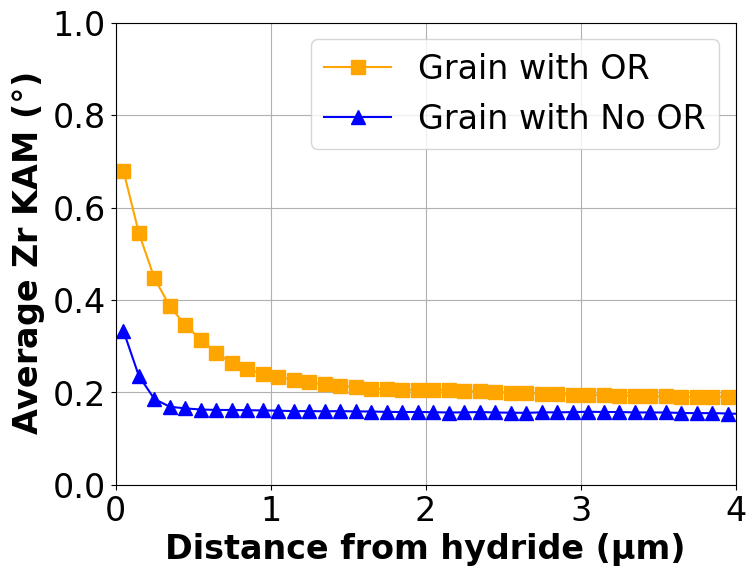

In [15]:
if section or slice_24 or slice_50:

    grainIDs_3d = np.squeeze(grainIDs)

    zr_g12_mask = zr_mask & (grainIDs_3d == 12)
    zr_g510_mask = zr_mask & (grainIDs_3d == 510)

    kam_zr_12 = kam[zr_g12_mask]
    kam_zr_510 = kam[zr_g510_mask]

    # GB voxels of the Zr phase, grain 12 (OR) and grain 510 (NoOR)
    gb_in_zr_12 = gb_all & zr_g12_mask
    gb_in_zr_510 = gb_all & zr_g510_mask

    # GB voxels touching hydride
    gb_zr_hyd_12 = gb_in_zr_12 & hyd_touch
    gb_zr_hyd_510 = gb_in_zr_510 & hyd_touch

    # Distance to Zr–hyd GB
    dist_gb_hyd_vol_12 = distance_transform_edt(~gb_zr_hyd_12, sampling=voxel_spacing)
    dist_gb_hyd_vol_510 = distance_transform_edt(~gb_zr_hyd_510, sampling=voxel_spacing)

    dist_gb_hyd_12 = dist_gb_hyd_vol_12[zr_g12_mask]
    dist_gb_hyd_510 = dist_gb_hyd_vol_510[zr_g510_mask]


    # Set bins
    bin_width = 0.1
    max_dist = 30.0
    bins = np.arange(0.0, max_dist + bin_width, bin_width)

    bin_centers_hydgb_12, bin_means_hydgb_12 = binned_mean(dist_gb_hyd_12, kam_zr_12, bins)
    bin_centers_hydgb_510, bin_means_hydgb_510 = binned_mean(dist_gb_hyd_510, kam_zr_510, bins)

    # Remove NaN values
    valid_12 = ~np.isnan(bin_means_hydgb_12)
    valid_510 = ~np.isnan(bin_means_hydgb_510)


    plt.figure(figsize=(8,6))
    plt.xlabel("Distance from hydride (µm)", fontsize=24, fontweight='bold')

    plt.plot(bin_centers_hydgb_12[valid_12], bin_means_hydgb_12[valid_12], marker='s', markersize=10, color='orange',label='Grain with OR')
    plt.plot(bin_centers_hydgb_510[valid_510], bin_means_hydgb_510[valid_510], marker='^',markersize=10, color='blue', label='Grain with No OR')

    plt.legend(fontsize=24)

    plt.ylabel("Average Zr KAM ($\degree$)", fontsize=24, fontweight='bold')
    plt.tick_params(axis='both', which='major', labelsize=24)

    plt.xlim([0, 4])
    plt.ylim([0, 1])
    plt.grid(True)

    plt.show()

### Plot KAM vs distance to hydride and vs distance to any GB, including hyd-zr and zr-zr GBs

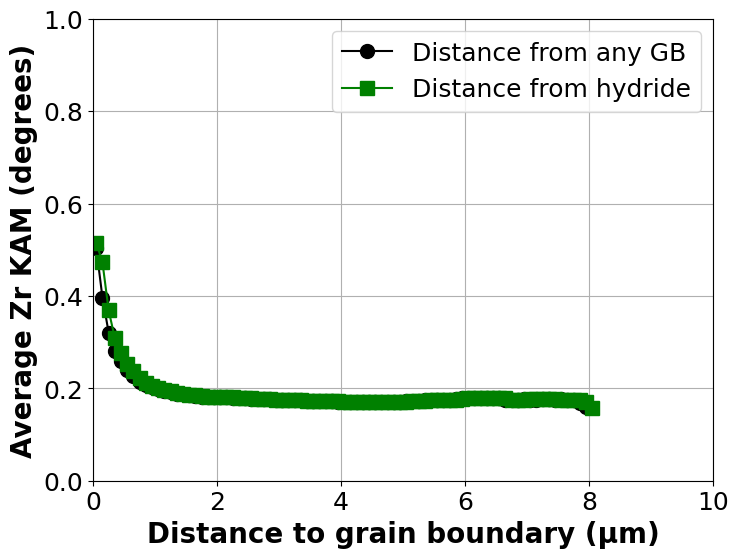

In [16]:

dist_to_hyd = distance_transform_edt(~hyd_mask, sampling=voxel_spacing)[zr_mask]
dist_gb = distance_transform_edt(~gb_all, sampling=voxel_spacing)[zr_mask]

kam_zr = kam[zr_mask]

## Set bins for plotting
bin_width = 0.1
max_dist = 30.0
bins = np.arange(0.0, max_dist + bin_width, bin_width)
bin_centers, bin_means = binned_mean(dist_gb, kam_zr, bins)
bin_centers_tohyd, bin_means_tohyd = binned_mean(dist_to_hyd, kam_zr, bins)

## Graphs

plt.figure(figsize=(8, 6))
plt.plot(bin_centers, bin_means, marker='o', color='black', markersize=10, label='Distance from any GB')
plt.plot(bin_centers_tohyd, bin_means_tohyd, marker='s', color='green', markersize=10, label='Distance from hydride')
plt.xlabel("Distance to grain boundary (µm)", fontsize=20, fontweight='bold')
plt.legend(fontsize=18)

plt.ylabel("Average Zr KAM (degrees)", fontsize=20, fontweight='bold')
plt.tick_params(axis='both', which='major', labelsize=18)

plt.xlim([0, 10])
plt.ylim([0, 1])
plt.grid(True)

plt.show()


In [17]:
len(dist_to_hyd) == len(dist_gb)

True

## Plot slice to test

In [18]:
if small_microstructure or larger_microstructure:
    fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
    # 1) Phases
    axes[0].imshow(ph[:, :, z], cmap='gray')
    axes[0].set_title("Hydrides")

    # 2) All GB voxels
    axes[1].imshow(gb_in_zr[:, :, z], cmap='gray')
    axes[1].set_title("All GB in Zr")

    # 3) Zr–hyd GB
    axes[2].imshow(gb_zr_hyd[:, :, z], cmap='gray')
    axes[2].set_title("Zr–hyd GB")

    # 4) Zr–Zr GB
    axes[3].imshow(gb_zr_zr[:, :, z], cmap='gray')
    axes[3].set_title("Zr–Zr GB")

    # 5) Zr–Zr GB ≥ 10 vox from hyd
    axes[4].imshow(gb_zr_zr_far[:, :, z], cmap='gray')
    axes[4].set_title("Zr–Zr GB far from hyd")

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.show()


### Slice showing both types of GB before thresholding

In [19]:
if small_microstructure or larger_microstructure:
    plt.figure(figsize=(5,5))
    plt.imshow(ph[:, :, z], cmap='gray')
    plt.imshow(gb_zr_hyd[:, :, z], cmap='Reds', alpha=0.7)
    plt.imshow(gb_zr_zr[:, :, z], cmap='Blues', alpha=0.7)

    plt.title("Overlay: Red = Zr–hyd GB, Blue = clean Zr–Zr GB")
    plt.axis('off')
    plt.show()


### Slice showing both types of GB after thresholding

In [20]:
if small_microstructure or larger_microstructure:
    plt.figure(figsize=(5,5))
    plt.imshow(ph[:, :, z], cmap='gray')
    plt.imshow(gb_zr_hyd[:, :, z], cmap='Reds', alpha=0.7)
    plt.imshow(gb_zr_zr_far[:, :, z], cmap='Blues', alpha=0.7)
    plt.title("Overlay: Red = Zr–hyd GB, Blue = clean Zr–Zr GB")
    plt.axis('off')
    plt.show()